# When to fly a thermal camera, advanced: slopes, shadows and forest on real terrain

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/thermal_timing_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [When to fly a thermal camera](https://openskylab.space/edu_viz_thermal_timing.html) · [česká verze](thermal_timing_pro_cs.ipynb)

The advanced version of the thermal timing notebook. The surface model from the basic version runs here for every four-metre cell of the real slope of the Vltava valley at Roztoky: with slope and aspect from DMR 5G, terrain shadows, forest and meadow from DMP 1G and the real direct and diffuse radiation from Open-Meteo. You find out when the terrain alone creates the largest and smallest differences in a thermal image and when forest and meadow cross over in temperature.

**Goal:** compute the Sun's position, the illumination of slopes and terrain shadows, run the surface energy balance for every cell of the area, compare meadow temperature by slope aspect during the day, and find the time of day when temperature is least affected by terrain, on a sunny and an overcast day.

**Data:** DMR 5G (terrain) and DMP 1G (surface) from ČÚZK, 4 m cells, a 1 × 0.7 km area on the left slope of the Vltava valley at Roztoky; hourly temperature, humidity, direct (on a normal surface) and diffuse radiation, cloud cover and wind from Open-Meteo for the last 92 days (weather model, not on-site measurement); thermal properties of meadow and forest as in the basic version. The model ignores cold air draining into the valley at night, radiation reflected from neighbouring slopes and changing soil moisture; DMP 1G dates from 2009–2013.

**Tasks:** four. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 55 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup, terrain and weather

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Window of a ČÚZK raster (dmr5g, dmp1g, dmp_obrazova_korelace) in S-JTSK (EPSG:5514), heights in Bpv.
    Returns the height array (row 0 = north) and its transform."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

terrain 175–252 m a.s.l., forest on 79% of the area, slope up to 55°


sunniest day 2026-08-24 (6.2 kWh/m²), most overcast 2026-10-25 (0.4 kWh/m²)


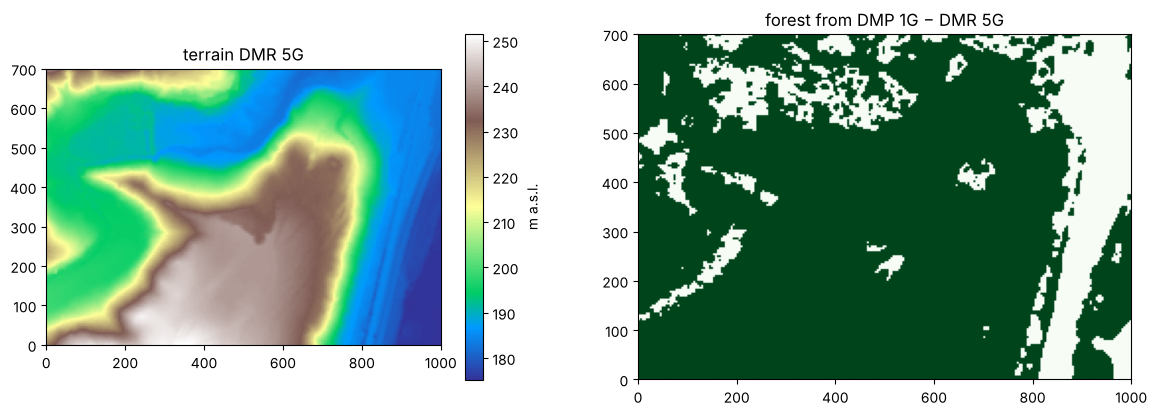

In [3]:
LAT, LON = 50.152, 14.392           # ◀ parameter: centre of the area (left slope of the Vltava valley at Roztoky)
W, Hh, RES = 1000, 700, 4.0         # width and height of the area (m), 4 m cells
FOREST_H = 5.0                      # ◀ parameter: vegetation height (m) from which a cell counts as forest
cx, cy = Transformer.from_crs(4326, 5514, always_xy=True).transform(LON, LAT)
box = (cx - W / 2, cy - Hh / 2, cx + W / 2, cy + Hh / 2)
dmr, _ = cuzk_raster("dmr5g", *box, res=RES)
dmp, _ = cuzk_raster("dmp1g", *box, res=RES)
forest = (dmp - dmr) > FOREST_H
gy, gx = np.gradient(dmr, RES)                         # rows run southwards
slope = np.arctan(np.hypot(gx, gy))
aspect = np.mod(np.arctan2(-gx, gy), 2 * np.pi)        # slope aspect (direction the slope faces), clockwise from north
print(f"terrain {dmr.min():.0f}–{dmr.max():.0f} m a.s.l., forest on {forest.mean():.0%} of the area, slope up to {np.degrees(slope).max():.0f}°")

j = open_meteo({"latitude": LAT, "longitude": LON, "past_days": 92, "forecast_days": 1, "timezone": "UTC", "wind_speed_unit": "ms",
                "hourly": "temperature_2m,relative_humidity_2m,shortwave_radiation,direct_normal_irradiance,diffuse_radiation,cloud_cover,wind_speed_10m"})
w = pd.DataFrame(j["hourly"]); w["time"] = pd.to_datetime(w.time); w = w.set_index("time").dropna()
days = w.shortwave_radiation.resample("D").sum().iloc[3:-1] / 1000      # kWh/m² per day; the first 3 days are spin-up
DAY, CLOUDY = days.idxmax().date(), days.idxmin().date()   # ◀ parameter: day to compute (default is the sunniest and the most overcast)
print(f"sunniest day {DAY} ({days.max():.1f} kWh/m²), most overcast {CLOUDY} ({days.min():.1f} kWh/m²)")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
im = ax[0].imshow(dmr, cmap="terrain", extent=(0, W, 0, Hh)); fig.colorbar(im, ax=ax[0], label="m a.s.l."); ax[0].set_title("terrain DMR 5G")
ax[1].imshow(forest, cmap="Greens", extent=(0, W, 0, Hh)); ax[1].set_title("forest from DMP 1G − DMR 5G"); plt.show()

## 2. Sun, slopes and shadows

Direct radiation falls on a slope in proportion to cos i, where i is the angle between the ray and the slope normal: cos i = cos z · cos s + sin z · sin s · cos(φ − A), z is the solar zenith angle, φ its azimuth, s the slope and A the slope aspect. A cell is in shadow when the terrain in the direction of the Sun blocks the ray. The maps show cos i, zero in shadow.

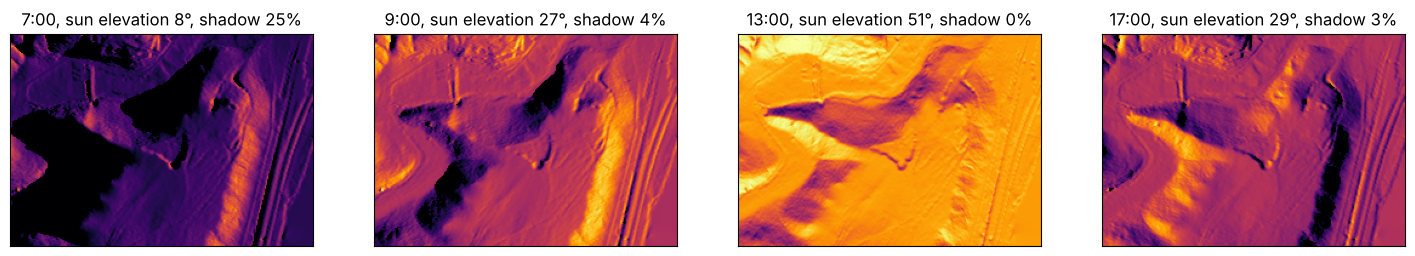

In [4]:
def sunpos(ts, lat, lon):
    """Solar zenith angle and azimuth (rad; azimuth clockwise from north) for times in UTC, NOAA formulas."""
    doy = ts.dayofyear.values; hr = ts.hour.values + ts.minute.values / 60
    g = 2 * np.pi / 365 * (doy - 1 + (hr - 12) / 24)
    eqt = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g) - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    dec = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g) + 0.000907 * np.sin(2 * g)
           - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    ha = np.radians((hr * 60 + eqt + 4 * lon) / 4 - 180)
    phi = np.radians(lat)
    z = np.arccos(np.clip(np.sin(phi) * np.sin(dec) + np.cos(phi) * np.cos(dec) * np.cos(ha), -1, 1))
    az = np.arctan2(np.sin(ha), np.cos(ha) * np.sin(phi) - np.tan(dec) * np.cos(phi)) + np.pi
    return z, np.mod(az, 2 * np.pi)

def shadow(z, az, dem=dmr, maxd=600):
    """Terrain shadow: a cell is shaded when some terrain in the direction of the Sun lies above the ray."""
    if z >= np.pi / 2:
        return np.ones(dem.shape, bool)
    ii, jj = np.mgrid[0:dem.shape[0], 0:dem.shape[1]]
    sh = np.zeros(dem.shape, bool)
    for d in np.arange(RES, maxd, RES):
        i2 = np.round(ii - np.cos(az) * d / RES).astype(int); j2 = np.round(jj + np.sin(az) * d / RES).astype(int)
        ok = (i2 >= 0) & (i2 < dem.shape[0]) & (j2 >= 0) & (j2 < dem.shape[1])
        sh[ok] |= dem[i2[ok], j2[ok]] > dem[ok] + d / np.tan(z)
    return sh

hours = [7, 9, 13, 17]              # ◀ parameter: local hours for the maps
when = pd.DatetimeIndex([pd.Timestamp(f"{DAY} {h}:00").tz_localize("Europe/Prague").tz_convert("UTC").tz_localize(None) for h in hours])
zs, azs = sunpos(when, LAT, LON)
fig, ax = plt.subplots(1, len(hours), figsize=(4.5 * len(hours), 3.5))
for a, h, z, az in zip(ax, hours, zs, azs):
    cosi = np.cos(z) * np.cos(slope) + np.sin(z) * np.sin(slope) * np.cos(az - aspect)
    direct = np.clip(cosi, 0, None) * ~shadow(z, az)
    a.imshow(direct, cmap="inferno", vmin=0, vmax=1, extent=(0, W, 0, Hh)); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{h}:00, sun elevation {90 - np.degrees(z):.0f}°, shadow {shadow(z, az).mean():.0%}")
plt.show()

> **✏️ Task 1.** Which parts of the area are in shadow at 7 o'clock, and why those? Why are east-facing slopes the most illuminated in the morning and west-facing ones at 17 o'clock, although the Sun is at a similar height at both times? What does this mean for a thermal image of the valley taken early in the morning?

*Your answer:* 

## 3. Surface temperature of every cell

The same energy balance as in the basic version runs for every cell, only the absorbed radiation is direct radiation times cos i (outside shadow) plus diffuse radiation times the fraction of the sky the cell sees. The meadow has soil with heat conduction into the depth, the forest is a thin layer of crowns. The model starts three days before the chosen day; the computation takes about a minute.

computed in 48 s, 175 × 250 cells, 48 times


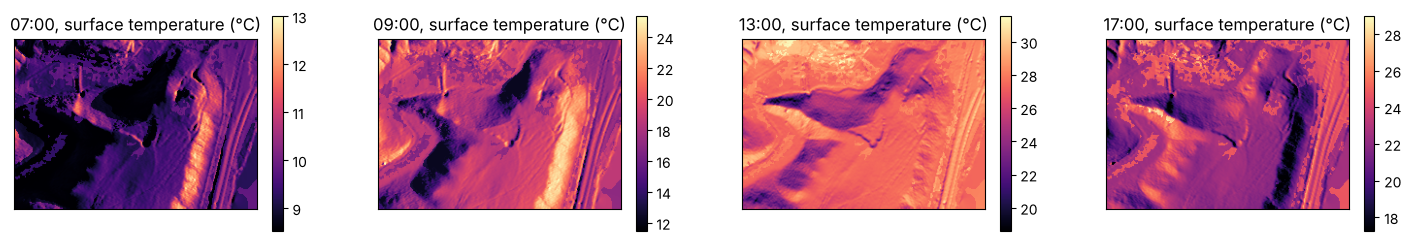

In [5]:
SIG = 5.670e-8
MEADOW = dict(alb=0.20, eps=0.98, k=1.2, C=2.5e6, rs=70.0)    # ◀ parameter: meadow (albedo, emissivity, conductivity, soil heat capacity, stomatal resistance)
FOREST = dict(alb=0.12, eps=0.98, rs=100.0, node=3.0e4, rough=3.0)   # ◀ parameter: forest (crowns as one thin layer)

def qsat(T):
    return 0.622 * 610.94 * np.exp(17.625 * (T - 273.15) / (T - 30.11)) / 101325

def run(day, terrain=True, dt=120, nl=12, depth=1.0):
    """Surface temperature of every cell every half hour of day; the model starts three days earlier."""
    ww = w[str(pd.Timestamp(day) - pd.Timedelta(days=3)): f"{day} 23:00"]
    t = (ww.index - ww.index[0]).total_seconds().values
    ts = np.arange(0, t[-1] + 3600, dt); times = ww.index[0] + pd.to_timedelta(ts, "s")
    Ta = np.interp(ts, t, ww.temperature_2m.values) + 273.15
    RH = np.interp(ts, t, ww.relative_humidity_2m.values) / 100
    DNI = np.interp(ts, t - 1800, ww.direct_normal_irradiance.values)    # radiation is the mean over the preceding hour
    DHI = np.interp(ts, t - 1800, ww.diffuse_radiation.values)
    cc = np.interp(ts, t, ww.cloud_cover.values) / 100
    U = np.maximum(np.interp(ts, t, ww.wind_speed_10m.values) * 0.75, 0.3)
    e = RH * 610.94 * np.exp(17.625 * (Ta - 273.15) / (Ta - 30.11))
    Ld = (1.24 * (e / 100 / Ta) ** (1 / 7) * (1 - cc) + cc) * SIG * Ta ** 4
    qa = RH * qsat(Ta)
    zen, azi = sunpos(times, LAT, LON)
    f = forest.ravel(); n = f.size
    s_ = slope.ravel() if terrain else np.zeros(n); a_ = aspect.ravel()
    svf = (1 + np.cos(s_)) / 2                              # fraction of the sky the cell sees
    alb = np.where(f, FOREST["alb"], MEADOW["alb"]); eps = np.where(f, FOREST["eps"], MEADOW["eps"])
    rs = np.where(f, FOREST["rs"], MEADOW["rs"]); rough = np.where(f, FOREST["rough"], 1.0)
    r = 1.0
    while 0.01 * (r ** nl - 1) / (r - 1 + 1e-12) < depth: r += 0.001
    dz = 0.01 * r ** np.arange(nl)
    cap = np.outer(np.full(n, MEADOW["C"]), dz); cap[f, 0] = FOREST["node"]; cap[f, 1:] = 1
    kk = np.outer(np.where(f, 0.0, MEADOW["k"]), 1 / ((dz[1:] + dz[:-1]) / 2))
    T = np.full((n, nl), Ta[: int(86400 / dt)].mean())
    rho, cp, L = 1.2, 1005, 2.45e6
    cache, outs, out_t = {}, [], []
    for i in range(len(ts)):
        sun = zen[i] < np.pi / 2
        if sun and terrain:
            key = int(ts[i] // 1200)                         # recompute the shadow every 20 min
            if key not in cache: cache = {key: shadow(zen[i], azi[i]).ravel()}
            lit = ~cache[key]
        else:
            lit = np.ones(n, bool)
        cosi = np.cos(zen[i]) * np.cos(s_) + np.sin(zen[i]) * np.sin(s_) * np.cos(azi[i] - a_)
        sw = DNI[i] * np.clip(cosi, 0, None) * lit * sun + DHI[i] * svf
        Ts = T[:, 0]; h = (5.7 + 3.8 * U[i]) * rough
        Rn = (1 - alb) * sw + eps * (Ld[i] * svf + (1 - svf) * SIG * Ta[i] ** 4 - SIG * Ts ** 4)
        H = h * (Ts - Ta[i]); LE = rho * L * (qsat(Ts) - qa[i]) / (rho * cp / h + rs)
        flux = kk * (T[:, :-1] - T[:, 1:])
        dT = np.zeros_like(T); dT[:, 0] = Rn - H - LE - flux[:, 0]; dT[:, 1:-1] = flux[:, :-1] - flux[:, 1:]; dT[:, -1] = flux[:, -1]
        T += dt * dT / cap
        if ts[i] % 1800 == 0 and times[i] >= pd.Timestamp(day):
            outs.append(T[:, 0].reshape(dmr.shape) - 273.15); out_t.append(times[i])
    return pd.DatetimeIndex(out_t).tz_localize("UTC").tz_convert("Europe/Prague"), np.array(outs)

t0 = time.time()
tt, TS = run(DAY)
print(f"computed in {time.time() - t0:.0f} s, {TS.shape[1]} × {TS.shape[2]} cells, {len(tt)} times")
fig, ax = plt.subplots(1, len(hours), figsize=(4.5 * len(hours), 3.5))
for a, h in zip(ax, hours):
    k = int(np.argmin(np.abs(tt.hour + tt.minute / 60 - h)))
    im = a.imshow(TS[k], cmap="magma", extent=(0, W, 0, Hh)); fig.colorbar(im, ax=a, shrink=0.8); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{tt[k]:%H:%M}, surface temperature (°C)")
plt.show()

In [6]:
mead = ~forest & (np.degrees(slope) > 10)            # meadows on slopes steeper than 10°
sector = pd.cut(np.degrees(aspect[mead]), [0, 45, 135, 225, 315, 360], labels=["N", "E", "S", "W", "N2"]).astype(str)
sector = np.where(sector == "N2", "N", sector)
rows = {}
for h in [7, 9, 13, 17, 21]:
    k = int(np.argmin(np.abs(tt.hour + tt.minute / 60 - h)))
    rows[f"{h}:00"] = pd.Series(TS[k][mead]).groupby(sector).median()
tab = pd.DataFrame(rows).loc[["N", "E", "S", "W"]]
tab.index = ["north", "east", "south", "west"]
print(f"meadows on slopes above 10°: {mead.sum()} cells; median surface temperature (°C) by slope aspect")
tab.round(1)

meadows on slopes above 10°: 1767 cells; median surface temperature (°C) by slope aspect


,7:00,9:00,13:00,17:00,21:00
north,9.3,15.0,25.0,23.8,14.5
east,10.7,19.7,29.2,23.0,14.4
south,9.6,17.6,30.3,25.9,14.9
west,9.3,13.6,26.5,26.3,14.7


> **✏️ Task 2.** By how many degrees do meadows on east-, south-, west- and north-facing slopes differ at 9 and at 13 o'clock? Why is the south slope warmest at 13 o'clock but the west slope at 17 o'clock? Why have the differences almost gone at 21 o'clock? What would follow for finding waterlogged spots in meadows from midday temperature?

*Your answer:* 

## 4. When the terrain interferes least

The spread of temperature between cells of the same surface (the difference between the 95th and 5th percentiles) shows how large differences in a thermal image the terrain alone creates, not differences in the surface. We compare the sunniest and the most overcast day and also follow the forest minus meadow difference.

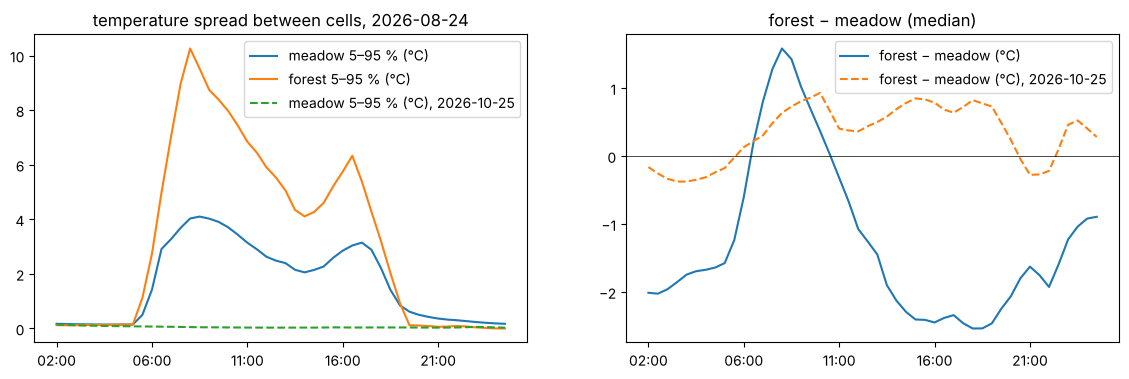

smallest meadow spread on the sunny day: 05:00 (0.14 °C)
forest and meadow cross over on the sunny day at about: ['07:00', '11:30']


In [7]:
def stats(tt, TS):
    m, f = ~forest, forest
    return pd.DataFrame({"meadow 5–95 % (°C)": [np.percentile(x[m], 95) - np.percentile(x[m], 5) for x in TS],
                         "forest 5–95 % (°C)": [np.percentile(x[f], 95) - np.percentile(x[f], 5) for x in TS],
                         "forest − meadow (°C)": [np.median(x[f]) - np.median(x[m]) for x in TS]}, index=tt.strftime("%H:%M"))
sun_day = stats(tt, TS)
tc, TC = run(CLOUDY)
cloud_day = stats(tc, TC)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sun_day[["meadow 5–95 % (°C)", "forest 5–95 % (°C)"]].plot(ax=ax[0], title=f"temperature spread between cells, {DAY}")
cloud_day[["meadow 5–95 % (°C)"]].rename(columns=lambda c: c + f", {CLOUDY}").plot(ax=ax[0], ls="--")
sun_day[["forest − meadow (°C)"]].plot(ax=ax[1], title="forest − meadow (median)"); cloud_day[["forest − meadow (°C)"]].rename(columns=lambda c: c + f", {CLOUDY}").plot(ax=ax[1], ls="--")
ax[1].axhline(0, color="k", lw=0.5); plt.show()
print("smallest meadow spread on the sunny day:", sun_day["meadow 5–95 % (°C)"].idxmin(), f"({sun_day['meadow 5–95 % (°C)'].min():.2f} °C)")
d = sun_day["forest − meadow (°C)"].values
print("forest and meadow cross over on the sunny day at about:", [sun_day.index[i] for i in range(len(d) - 1) if np.sign(d[i]) != np.sign(d[i + 1])])

> **✏️ Task 3.** At what time of day is the meadow temperature spread smallest, and how long after sunset does it take for the differences between slopes to disappear? Why do they not disappear immediately? Change the thermal conductivity `k` in `MEADOW` to 0.6 (dry soil) and watch how this changes. How large is the spread on the overcast day, and why?

*Your answer:* 

> **✏️ Task 4.** When do forest and meadow cross over in temperature on the sunny day, and how does this differ from the overcast day? The model ignores cold air draining into the valley. How would a real pre-dawn thermal image of the valley look different from the model, and why might the smallest spread then not be just before dawn?

*Your answer:* 

> **✏️ Extension (optional).** Set `LAT, LON` to the slope above the Brno reservoir (49.2467, 16.4798) or to the valley near Hosín by Hluboká nad Vltavou (49.0452, 14.4769) and compare shadows, differences by slope aspect and the time of the smallest spread.

*Your answer:* 

---
### Data sources and references

- Digital terrain model of the Czech Republic, 5th generation (DMR 5G) and digital surface model, 1st generation (DMP 1G), © ČÚZK, licence CC BY 4.0, services https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer and https://ags.cuzk.cz/arcgis2/rest/services/dmp1g/ImageServer
- Weather: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- Solar position: NOAA Global Monitoring Laboratory, *General Solar Position Calculations* (formulas for declination and the equation of time).
- Brutsaert, W. (1975). On a derivable formula for long-wave radiation from clear skies. *Water Resources Research* 11, 742–744.
- Oke, T. R. (1987). *Boundary Layer Climates*, 2nd ed. Routledge (thermal properties of soil, albedos, local climate of slopes).
- Maes, W. H. (2025). Practical guidelines for performing UAV mapping flights with snapshot sensors. *Remote Sensing* 17(4), 606. https://doi.org/10.3390/rs17040606

### How to cite

OpenSkyLab (2026). When to fly a thermal camera, advanced: slopes, shadows and forest on real terrain [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/thermal_timing_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*